<a href="https://colab.research.google.com/github/Preksha-ML/Rock_vs_mine-project/blob/main/Rocks_vs_Mines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [22]:
df = pd.read_csv('/Sonar.csv')

In [23]:
df.head(5)

,Freq_1,Freq_2,Freq_3,Freq_4,Freq_5,Freq_6,Freq_7,Freq_8,Freq_9,Freq_10,...,Freq_52,Freq_53,Freq_54,Freq_55,Freq_56,Freq_57,Freq_58,Freq_59,Freq_60,Label
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [24]:
df['Label'].value_counts()


,count
Label,
M,111
R,97


In [25]:
df.columns

Index(['Freq_1', 'Freq_2', 'Freq_3', 'Freq_4', 'Freq_5', 'Freq_6', 'Freq_7',
       'Freq_8', 'Freq_9', 'Freq_10', 'Freq_11', 'Freq_12', 'Freq_13',
       'Freq_14', 'Freq_15', 'Freq_16', 'Freq_17', 'Freq_18', 'Freq_19',
       'Freq_20', 'Freq_21', 'Freq_22', 'Freq_23', 'Freq_24', 'Freq_25',
       'Freq_26', 'Freq_27', 'Freq_28', 'Freq_29', 'Freq_30', 'Freq_31',
       'Freq_32', 'Freq_33', 'Freq_34', 'Freq_35', 'Freq_36', 'Freq_37',
       'Freq_38', 'Freq_39', 'Freq_40', 'Freq_41', 'Freq_42', 'Freq_43',
       'Freq_44', 'Freq_45', 'Freq_46', 'Freq_47', 'Freq_48', 'Freq_49',
       'Freq_50', 'Freq_51', 'Freq_52', 'Freq_53', 'Freq_54', 'Freq_55',
       'Freq_56', 'Freq_57', 'Freq_58', 'Freq_59', 'Freq_60', 'Label'],
      dtype='object')

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Freq_1   208 non-null    float64
 1   Freq_2   208 non-null    float64
 2   Freq_3   208 non-null    float64
 3   Freq_4   208 non-null    float64
 4   Freq_5   208 non-null    float64
 5   Freq_6   208 non-null    float64
 6   Freq_7   208 non-null    float64
 7   Freq_8   208 non-null    float64
 8   Freq_9   208 non-null    float64
 9   Freq_10  208 non-null    float64
 10  Freq_11  208 non-null    float64
 11  Freq_12  208 non-null    float64
 12  Freq_13  208 non-null    float64
 13  Freq_14  208 non-null    float64
 14  Freq_15  208 non-null    float64
 15  Freq_16  208 non-null    float64
 16  Freq_17  208 non-null    float64
 17  Freq_18  208 non-null    float64
 18  Freq_19  208 non-null    float64
 19  Freq_20  208 non-null    float64
 20  Freq_21  208 non-null    float64
 21  Freq_22  208 non

In [27]:
X = df.drop(["Label"], axis = 1)
y = df["Label"]

In [28]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.20, random_state = 42 )

In [57]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [41]:
from sklearn.ensemble import IsolationForest

iso_model = IsolationForest(contamination=0.1, random_state=42)

iso_model.fit(X_train)

y_pred_iso = iso_model.predict(X_test)

print('Predictions sample:', y_pred_iso[:20])

Predictions sample: [ 1  1  1  1  1  1 -1 -1  1  1  1  1  1  1  1  1  1  1  1  1]


In [48]:
y_pred_iso_mapped_one = np.where(y_pred_iso == 1, 'R', 'M')
print('Mapped Predictions Sample:', y_pred_iso_mapped_one[:20])

Mapped Predictions Sample: ['R' 'R' 'R' 'R' 'R' 'R' 'M' 'M' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R'
 'R' 'R']


Accuracy: 0.5238095238095238
              precision    recall  f1-score   support

           M       0.88      0.27      0.41        26
           R       0.44      0.94      0.60        16

    accuracy                           0.52        42
   macro avg       0.66      0.60      0.51        42
weighted avg       0.71      0.52      0.48        42



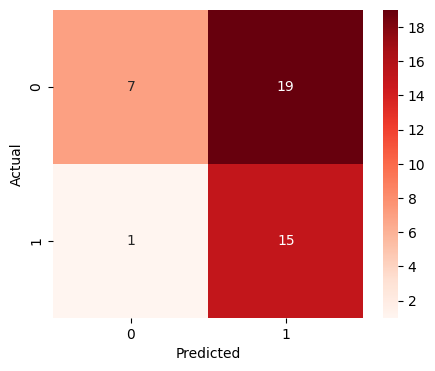

In [61]:
y_pred_iso_mapped_one_accuracy_score = accuracy_score(y_test, y_pred_iso_mapped_one)
print("Accuracy:", y_pred_iso_mapped_one_accuracy_score )
print(classification_report(y_test, y_pred_iso_mapped_one))

cm = confusion_matrix(y_test, y_pred_iso_mapped_one)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [47]:
y_pred_iso_mapped_two = np.where(y_pred_iso == 1, 'M', 'R')
print('Mapped Predictions Sample:', y_pred_iso_mapped_two[:20])

Mapped Predictions Sample: ['M' 'M' 'M' 'M' 'M' 'M' 'R' 'R' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M'
 'M' 'M']


Accuracy: 0.47619047619047616
              precision    recall  f1-score   support

           M       0.56      0.73      0.63        26
           R       0.12      0.06      0.08        16

    accuracy                           0.48        42
   macro avg       0.34      0.40      0.36        42
weighted avg       0.39      0.48      0.42        42



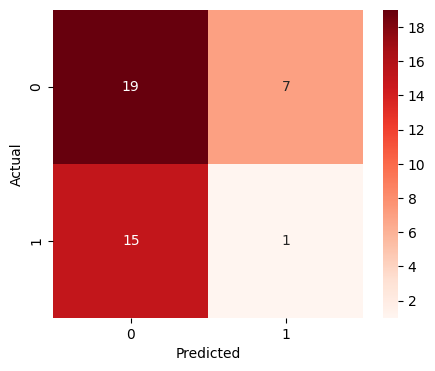

In [50]:
y_pred_iso_mapped_two_accuracy_score = accuracy_score(y_test, y_pred_iso_mapped_two)
print("Accuracy:", y_pred_iso_mapped_two_accuracy_score )
print(classification_report(y_test, y_pred_iso_mapped_two))

cm = confusion_matrix(y_test, y_pred_iso_mapped_two)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [51]:
from sklearn.linear_model import LogisticRegression
# Model train karein
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predictions aur Accuracy
lr_pred = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_acc * 100)

Logistic Regression Accuracy: 78.57142857142857


In [53]:
from sklearn.svm import SVC

# Model train karein
svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

# Predictions aur Accuracy
svm_pred = svm_model.predict(X_test)
svm_acc = accuracy_score(y_test, svm_pred)
print("SVM Accuracy:", svm_acc * 100)

SVM Accuracy: 83.33333333333334


In [54]:
from sklearn.neighbors import KNeighborsClassifier

# Model train karein
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Predictions aur Accuracy
knn_pred = knn_model.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)
print("KNN Accuracy:", knn_acc * 100)

KNN Accuracy: 85.71428571428571


In [55]:
from sklearn.ensemble import GradientBoostingClassifier

# Model train karein
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predictions aur Accuracy
gb_pred = gb_model.predict(X_test)
gb_acc = accuracy_score(y_test, gb_pred)
print("Gradient Boosting Accuracy:", gb_acc * 100)

Gradient Boosting Accuracy: 78.57142857142857


In [58]:
from sklearn.ensemble import RandomForestClassifier

# Model train karein
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Predictions aur Accuracy
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_acc * 100)

Random Forest Accuracy: 85.71428571428571


             Algorithm  Accuracy (%)
0        Random Forest     88.095238
1  Logistic Regression     78.571429
2                  SVM     83.333333
3                  KNN     85.714286
4    Gradient Boosting     78.571429
5     Isolation Forest     52.380952


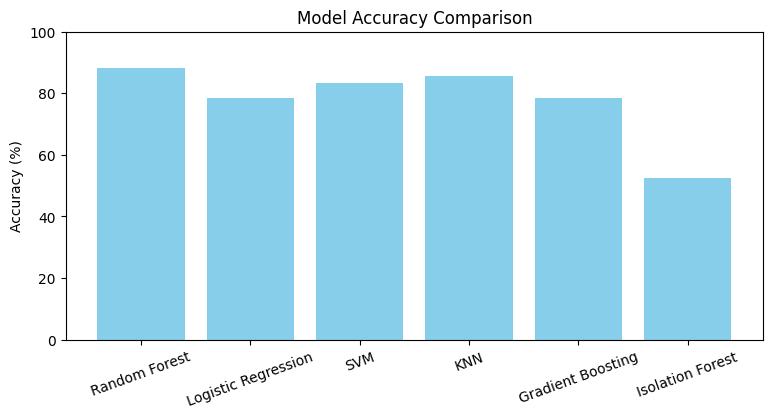

In [62]:
# Sabhi accuracies ka ek simple dictionary
results = {
    "Random Forest": model.score(X_test, y_test) * 100,  # Aapka pehle se trained RF model
    "Logistic Regression": lr_acc * 100,
    "SVM": svm_acc * 100,
    "KNN": knn_acc * 100,
    "Gradient Boosting": gb_acc * 100,
    "Isolation Forest" : y_pred_iso_mapped_one_accuracy_score * 100,
}

# Dataframe banana
df_res = pd.DataFrame(
    list(results.items()), columns=["Algorithm", "Accuracy (%)"]
)
print(df_res)

# Simple Bar Chart
plt.figure(figsize=(9, 4))
plt.bar(df_res["Algorithm"], df_res["Accuracy (%)"], color="skyblue")
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.show()

In [73]:
import joblib
joblib.dump(rf_model, 'sonar_model.pkl')

['sonar_model.pkl']

In [74]:
from google.colab import files
files.download("sonar_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>